# Práctica: Red de Funciones de Base Radial (RBF)

Clasificación del estado de una máquina con temperatura y vibración. Este cuaderno cubre desde la Actividad 5 hasta los experimentos y gráficas requeridas.

## Datos, partición y normalización

La separación es estratificada. Los parámetros de normalización se calculan con entrenamiento y se aplican sin cambios a prueba.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 42

def cargar_datos():
    # Temperatura, vibración y etiqueta (0: Normal, 1: Falla).
    datos = np.array([
        [0.45,0.45,0], [0.50,0.55,0], [0.55,0.48,0], [0.42,0.52,0],
        [0.58,0.56,0], [0.50,0.40,0], [0.40,0.45,0], [0.60,0.50,0],
        [0.10,0.10,1], [0.15,0.80,1], [0.85,0.15,1], [0.90,0.90,1],
        [0.20,0.60,1], [0.75,0.85,1], [0.80,0.50,1], [0.50,0.90,1]
    ], dtype=float)
    return datos[:, :2], datos[:, 2].astype(int)

def dividir_estratificado(X, y, proporcion=0.75, semilla=42):
    rng = np.random.default_rng(semilla)
    train, prueba = [], []
    for clase in np.unique(y):
        indices = np.where(y == clase)[0]
        rng.shuffle(indices)
        corte = int(round(len(indices) * proporcion))
        train.extend(indices[:corte])
        prueba.extend(indices[corte:])
    return np.array(train), np.array(prueba)

def normalizar(X):
    minimo, maximo = X.min(axis=0), X.max(axis=0)
    return (X - minimo) / (maximo - minimo), minimo, maximo

def aplicar_normalizacion(X, minimo, maximo):
    return (X - minimo) / (maximo - minimo)

X, y = cargar_datos()
ids_train, ids_test = dividir_estratificado(X, y, semilla=SEMILLA)
X_train_sin_norm, X_test_sin_norm = X[ids_train], X[ids_test]
y_train, y_test = y[ids_train], y[ids_test]
X_train, minimo, maximo = normalizar(X_train_sin_norm)
X_test = aplicar_normalizacion(X_test_sin_norm, minimo, maximo)

print(f'Entrenamiento: {len(X_train)} patrones')
print(f'Prueba: {len(X_test)} patrones')

Entrenamiento: 12 patrones
Prueba: 4 patrones


## Implementación de K-means y de la capa RBF

Los centros se obtienen únicamente con los patrones de entrenamiento. Si un grupo queda vacío, se reubica en el patrón peor representado.

In [2]:
def distancia_euclidiana(X, centros):
    return np.sqrt(((X[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2))

def k_means(X, k, semilla=42, max_iter=100):
    rng = np.random.default_rng(semilla)
    centros = X[rng.choice(len(X), size=k, replace=False)].copy()
    for _ in range(max_iter):
        distancias = distancia_euclidiana(X, centros)
        grupos = distancias.argmin(axis=1)
        nuevos = centros.copy()
        for j in range(k):
            puntos = X[grupos == j]
            if len(puntos):
                nuevos[j] = puntos.mean(axis=0)
            else:
                error = distancias[np.arange(len(X)), grupos]
                nuevos[j] = X[error.argmax()]
        if np.allclose(nuevos, centros, atol=1e-8):
            centros = nuevos
            break
        centros = nuevos
    return centros, distancia_euclidiana(X, centros).argmin(axis=1)

def calcular_sigma(centros):
    dmax = distancia_euclidiana(centros, centros).max()
    return dmax / np.sqrt(2 * len(centros))

def capa_rbf(X, centros, sigma):
    d2 = ((X[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2)
    return np.exp(-d2 / (2 * sigma ** 2))

centros, grupos = k_means(X_train, 4, SEMILLA)
sigma = calcular_sigma(centros)
print('Centros de K-means:\n', np.round(centros, 4))
print('Sigma:', round(sigma, 4))
print('Patrones por centro:', np.bincount(grupos, minlength=4))

Centros de K-means:
 [[0.7    0.9688]
 [0.5444 0.5125]
 [0.0667 0.5   ]
 [1.     0.0625]]
Sigma: 0.3644
Patrones por centro: [2 6 3 1]


## Entrenamiento de la salida

Centros y sigma permanecen fijos. Solo se ajustan los pesos de salida y el sesgo con descenso de gradiente estocástico.

In [3]:
def sigmoide(z):
    return 1 / (1 + np.exp(-np.clip(z, -40, 40)))

def entropia_cruzada(y_real, probabilidad):
    probabilidad = np.clip(probabilidad, 1e-12, 1 - 1e-12)
    return -np.mean(y_real*np.log(probabilidad) + (1-y_real)*np.log(1-probabilidad))

def entrenar_salida(phi_train, y_train, phi_test, y_test, epocas=500, tasa=0.10):
    pesos, sesgo, historial = np.zeros(phi_train.shape[1]), 0.0, []
    for epoca in range(epocas + 1):
        if epoca % 50 == 0:
            p_train = sigmoide(phi_train @ pesos + sesgo)
            p_test = sigmoide(phi_test @ pesos + sesgo)
            acc_train = ((p_train >= .5).astype(int) == y_train).mean()
            acc_test = ((p_test >= .5).astype(int) == y_test).mean()
            historial.append([epoca, entropia_cruzada(y_train, p_train), acc_train, acc_test])
        if epoca == epocas:
            break
        # Cada actualización se usa inmediatamente en el siguiente patrón.
        for phi, etiqueta in zip(phi_train, y_train):
            prediccion = sigmoide(phi @ pesos + sesgo)
            delta = prediccion - etiqueta
            pesos -= tasa * delta * phi
            sesgo -= tasa * delta
    return pesos, sesgo, np.array(historial)

def predecir(X, centros, sigma, pesos, sesgo):
    return sigmoide(capa_rbf(X, centros, sigma) @ pesos + sesgo)

phi_train = capa_rbf(X_train, centros, sigma)
phi_test = capa_rbf(X_test, centros, sigma)
pesos, sesgo, historial = entrenar_salida(phi_train, y_train, phi_test, y_test)

print('Pesos:', np.round(pesos, 4))
print('Sesgo:', round(sesgo, 4))
print('Época | Pérdida train | Acc. train | Acc. prueba')
for e, perdida, acc_t, acc_p in historial:
    print(f'{int(e):5d} | {perdida:.4f}         | {acc_t:.2f}       | {acc_p:.2f}')

Pesos: [  2.0686 -12.0689   2.2704   0.0948]
Sesgo: 5.9622
Época | Pérdida train | Acc. train | Acc. prueba
    0 | 0.6931         | 0.50       | 0.50
   50 | 0.2259         | 1.00       | 1.00
  100 | 0.1294         | 1.00       | 1.00
  150 | 0.0903         | 1.00       | 1.00
  200 | 0.0694         | 1.00       | 1.00
  250 | 0.0564         | 1.00       | 1.00
  300 | 0.0475         | 1.00       | 1.00
  350 | 0.0410         | 1.00       | 1.00
  400 | 0.0361         | 1.00       | 1.00
  450 | 0.0323         | 1.00       | 1.00
  500 | 0.0292         | 1.00       | 1.00


## Matriz de confusión y métricas

In [4]:
def matriz_confusion(y_real, probabilidades):
    pred = (probabilidades >= .5).astype(int)
    vp = int(((y_real == 1) & (pred == 1)).sum())
    fn = int(((y_real == 1) & (pred == 0)).sum())
    fp = int(((y_real == 0) & (pred == 1)).sum())
    vn = int(((y_real == 0) & (pred == 0)).sum())
    return np.array([[vp, fn], [fp, vn]])

def metricas(y_real, probabilidades):
    vp, fn, fp, vn = matriz_confusion(y_real, probabilidades).ravel()
    div = lambda a, b: a/b if b else 0.0
    return {'VP':vp, 'FN':fn, 'FP':fp, 'VN':vn,
            'exactitud':div(vp+vn, vp+fn+fp+vn),
            'precision':div(vp, vp+fp),
            'sensibilidad':div(vp, vp+fn),
            'especificidad':div(vn, vn+fp)}

prob_train = predecir(X_train, centros, sigma, pesos, sesgo)
prob_test = predecir(X_test, centros, sigma, pesos, sesgo)
print('Matriz de prueba [ [VP, FN], [FP, VN] ]:\n', matriz_confusion(y_test, prob_test))
print('Entrenamiento:', metricas(y_train, prob_train))
print('Prueba:', metricas(y_test, prob_test))

Matriz de prueba [ [VP, FN], [FP, VN] ]:
 [[2 0]
 [0 2]]
Entrenamiento: {'VP': np.int64(6), 'FN': np.int64(0), 'FP': np.int64(0), 'VN': np.int64(6), 'exactitud': np.float64(1.0), 'precision': np.float64(1.0), 'sensibilidad': np.float64(1.0), 'especificidad': np.float64(1.0)}
Prueba: {'VP': np.int64(2), 'FN': np.int64(0), 'FP': np.int64(0), 'VN': np.int64(2), 'exactitud': np.float64(1.0), 'precision': np.float64(1.0), 'sensibilidad': np.float64(1.0), 'especificidad': np.float64(1.0)}


## Gráficas requeridas: datos y frontera, pérdida y exactitud

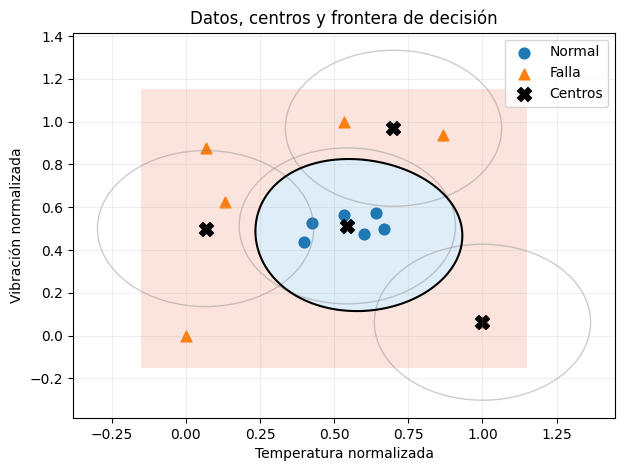

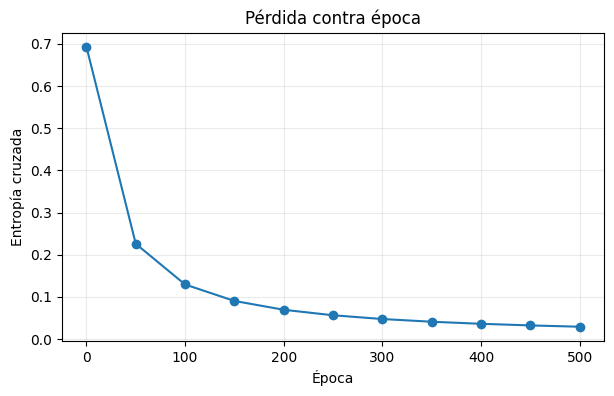

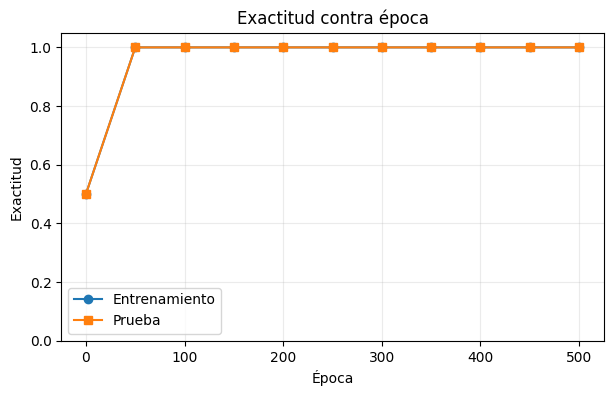

In [5]:
# La malla permite visualizar dónde cambia la predicción entre Normal y Falla.
margen = .15
eje_x = np.linspace(X_train[:,0].min()-margen, X_train[:,0].max()+margen, 220)
eje_y = np.linspace(X_train[:,1].min()-margen, X_train[:,1].max()+margen, 220)
xx, yy = np.meshgrid(eje_x, eje_y)
zz = predecir(np.c_[xx.ravel(), yy.ravel()], centros, sigma, pesos, sesgo).reshape(xx.shape)

plt.figure(figsize=(7,5))
plt.contourf(xx, yy, zz, levels=[0,.5,1], colors=['#b8d8f0','#f7c5b7'], alpha=.45)
plt.contour(xx, yy, zz, levels=[.5], colors='black')
for clase, marca, nombre in [(0,'o','Normal'),(1,'^','Falla')]:
    ids = y_train == clase
    plt.scatter(X_train[ids,0], X_train[ids,1], marker=marca, s=60, label=nombre)
plt.scatter(centros[:,0], centros[:,1], c='black', marker='X', s=100, label='Centros')
for centro in centros:
    plt.gca().add_patch(plt.Circle(centro, sigma, fill=False, color='gray', alpha=.4))
plt.title('Datos, centros y frontera de decisión'); plt.xlabel('Temperatura normalizada'); plt.ylabel('Vibración normalizada')
plt.legend(); plt.grid(alpha=.2); plt.show()

plt.figure(figsize=(7,4))
plt.plot(historial[:,0], historial[:,1], marker='o')
plt.title('Pérdida contra época'); plt.xlabel('Época'); plt.ylabel('Entropía cruzada'); plt.grid(alpha=.25); plt.show()

plt.figure(figsize=(7,4))
plt.plot(historial[:,0], historial[:,2], marker='o', label='Entrenamiento')
plt.plot(historial[:,0], historial[:,3], marker='s', label='Prueba')
plt.ylim(0,1.05); plt.title('Exactitud contra época'); plt.xlabel('Época'); plt.ylabel('Exactitud')
plt.legend(); plt.grid(alpha=.25); plt.show()

## Experimentos obligatorios

Se modifica una condición a la vez: K, sigma, forma de elegir centros y el perceptrón monocapa.

In [6]:
def entrenar_rbf(X_train, y_train, X_test, y_test, k=4, sigma_fijo=None, metodo='kmeans'):
    if metodo == 'kmeans':
        centros_local, _ = k_means(X_train, k, SEMILLA)
    else:
        rng = np.random.default_rng(SEMILLA)
        centros_local = X_train[rng.choice(len(X_train), k, replace=False)].copy()
    sigma_local = calcular_sigma(centros_local) if sigma_fijo is None else sigma_fijo
    f_train = capa_rbf(X_train, centros_local, sigma_local)
    f_test = capa_rbf(X_test, centros_local, sigma_local)
    w, b, _ = entrenar_salida(f_train, y_train, f_test, y_test)
    p_test = sigmoide(f_test @ w + b)
    return sigma_local, entropia_cruzada(y_test, p_test), metricas(y_test, p_test)

def entrenar_perceptron(X_train, y_train, X_test, y_test, epocas=500, tasa=.10):
    w, b = np.zeros(2), 0.0
    for _ in range(epocas):
        for x, etiqueta in zip(X_train, y_train):
            delta = sigmoide(x @ w + b) - etiqueta
            w -= tasa * delta * x
            b -= tasa * delta
    p_test = sigmoide(X_test @ w + b)
    return entropia_cruzada(y_test, p_test), metricas(y_test, p_test)

configuraciones = [
    ('RBF base', dict()), ('RBF K=2', dict(k=2)), ('RBF K=6', dict(k=6)),
    ('RBF sigma=0.10', dict(sigma_fijo=.10)), ('RBF sigma=0.25', dict(sigma_fijo=.25)),
    ('RBF sigma=0.50', dict(sigma_fijo=.50)), ('RBF centros aleatorios', dict(metodo='aleatorio'))
]
filas = []
for nombre, argumentos in configuraciones:
    sigma_exp, perdida, m = entrenar_rbf(X_train, y_train, X_test, y_test, **argumentos)
    filas.append((nombre, sigma_exp, perdida, m['exactitud']))
perdida, m = entrenar_perceptron(X_train, y_train, X_test, y_test)
filas.append(('Perceptrón monocapa', np.nan, perdida, m['exactitud']))

print('Modelo                     | Sigma  | Pérdida prueba | Exactitud prueba')
for nombre, sigma_exp, perdida, exactitud in filas:
    texto_sigma = '-' if np.isnan(sigma_exp) else f'{sigma_exp:.4f}'
    print(f'{nombre:26s} | {texto_sigma:6s} | {perdida:.4f}          | {exactitud:.2f}')

Modelo                     | Sigma  | Pérdida prueba | Exactitud prueba
RBF base                   | 0.3644 | 0.1791          | 1.00
RBF K=2                    | 0.2505 | 0.0969          | 1.00
RBF K=6                    | 0.3450 | 0.1839          | 0.75
RBF sigma=0.10             | 0.1000 | 0.0628          | 1.00
RBF sigma=0.25             | 0.2500 | 0.0627          | 1.00
RBF sigma=0.50             | 0.5000 | 0.2643          | 0.75
RBF centros aleatorios     | 0.3653 | 0.0953          | 1.00
Perceptrón monocapa        | -      | 0.7975          | 0.00


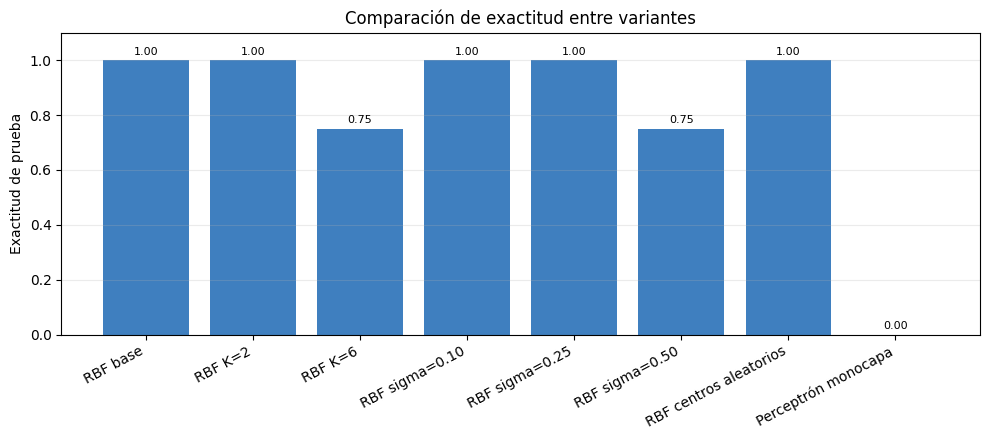

Nota: en la prueba hay 4 patrones; un error modifica la exactitud en 0.25.


In [7]:
# Cuarta gráfica solicitada: comparación entre las variantes.
nombres = [fila[0] for fila in filas]
exactitudes = [fila[3] for fila in filas]
plt.figure(figsize=(10,4.5))
barras = plt.bar(range(len(nombres)), exactitudes, color='#3f7fbf')
plt.xticks(range(len(nombres)), nombres, rotation=28, ha='right')
plt.ylim(0,1.1); plt.ylabel('Exactitud de prueba'); plt.title('Comparación de exactitud entre variantes')
plt.grid(axis='y', alpha=.25)
for barra, valor in zip(barras, exactitudes):
    plt.text(barra.get_x()+barra.get_width()/2, valor+.02, f'{valor:.2f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()
print('Nota: en la prueba hay 4 patrones; un error modifica la exactitud en 0.25.')